# PRT Ridership Recovery Analysis

## Research Question
How did weekday ridership recovery after COVID-19 differ across Pittsburgh Regional Transit bus, rail, and incline service compared with 2019 levels?

In [1]:
import pandas as pd

In [2]:
prt = pd.read_csv("Data/prt_monthly_ridership_clean.csv")

## Data Preparation

This analysis uses the cleaned PRT monthly ridership dataset. I limited the data to weekday ridership from 2019 through 2025 because 2019 is the pre-COVID baseline and 2026 is only a partial year.

MNT and MNT1 were excluded from the analysis because their mode classifications were inconsistent and their ridership totals were very small.

In [3]:
analysis_ready = prt.loc[
    (prt["Day_Type"] == "WEEKDAY") &
    (prt["Year"].between(2019, 2025)) &
    (~prt["Route"].isin(["MNT", "MNT1"]))
].copy()

In [4]:
analysis_ready.shape

(8309, 10)

## Data Quality and Confounding Variables

Before calculating recovery, I checked for issues that could affect the results. This included route counts by mode, missing months, seasonality, and changes in route coding.

Bus and rail had complete monthly coverage from 2019 through 2025. Incline data were incomplete in 2022, 2023, and 2024, and incline ridership also showed strong seasonality. Because of this, incline recovery was calculated using matched months rather than full-year averages.

In [5]:
analysis_ready.groupby(["Year", "Mode"])["Route"].nunique()

Year  Mode   
2019  Bus        96
      Incline     1
      Rail        3
2020  Bus        95
      Incline     1
      Rail        3
2021  Bus        96
      Incline     1
      Rail        3
2022  Bus        95
      Incline     1
      Rail        3
2023  Bus        95
      Incline     1
      Rail        3
2024  Bus        96
      Incline     1
      Rail        4
2025  Bus        95
      Incline     1
      Rail        4
Name: Route, dtype: int64

In [6]:
analysis_ready[
    analysis_ready["Mode"] == "Rail"
].groupby("Year")["Route"].unique()

Year
2019         [BLUE, RED, SLVR]
2020         [BLUE, RED, SLVR]
2021         [BLUE, RED, SLVR]
2022         [BLUE, RED, SLVR]
2023         [BLUE, RED, SLVR]
2024    [BLUE, RED, SLVR, SWL]
2025    [BLUE, RED, SLVR, SWL]
Name: Route, dtype: object

In [7]:
analysis_ready.groupby(["Year", "Mode"])["Month_Start"].nunique()

Year  Mode   
2019  Bus        12
      Incline    12
      Rail       12
2020  Bus        12
      Incline    12
      Rail       12
2021  Bus        12
      Incline    12
      Rail       12
2022  Bus        12
      Incline     7
      Rail       12
2023  Bus        12
      Incline    10
      Rail       12
2024  Bus        12
      Incline    11
      Rail       12
2025  Bus        12
      Incline    12
      Rail       12
Name: Month_Start, dtype: int64

In [8]:
analysis_ready.loc[
    analysis_ready["Mode"] == "Incline",
    ["Year", "Month_Start", "Avg_Riders"]
].sort_values(["Year", "Month_Start"])

,Year,Month_Start,Avg_Riders
21020,2019,2019-01-01,676.818182
20793,2019,2019-02-01,187.050000
20564,2019,2019-03-01,236.904762
20335,2019,2019-04-01,286.727273
20106,2019,2019-05-01,861.136364
...,...,...,...
2167,2025,2025-08-01,790.904762
1923,2025,2025-09-01,418.761905
1679,2025,2025-10-01,471.217391
1435,2025,2025-11-01,81.526316


In [9]:
for year in [2022, 2023, 2024]:
    months_present = analysis_ready.loc[
        (analysis_ready["Mode"] == "Incline") &
        (analysis_ready["Year"] == year),
        "Month_Start"
    ]
    print(year, list(months_present))

2022 ['2022-07-01', '2022-06-01', '2022-05-01', '2022-04-01', '2022-03-01', '2022-02-01', '2022-01-01']
2023 ['2023-12-01', '2023-11-01', '2023-10-01', '2023-09-01', '2023-08-01', '2023-07-01', '2023-06-01', '2023-05-01', '2023-04-01', '2023-03-01']
2024 ['2024-12-01', '2024-11-01', '2024-10-01', '2024-09-01', '2024-08-01', '2024-07-01', '2024-06-01', '2024-05-01', '2024-04-01', '2024-03-01', '2024-02-01']


In [10]:
prt.loc[
    (prt["Mode"] == "Incline") &
    (
        ((prt["Year"] == 2022) & (pd.to_datetime(prt["Month_Start"]).dt.month >= 8)) |
        ((prt["Year"] == 2023) & (pd.to_datetime(prt["Month_Start"]).dt.month <= 2)) |
        ((prt["Year"] == 2024) & (pd.to_datetime(prt["Month_Start"]).dt.month == 1))
    ),
    ["Year", "Month_Start", "Day_Type", "Avg_Riders"]
].sort_values(["Month_Start", "Day_Type"])

,Year,Month_Start,Day_Type,Avg_Riders
6720,2024,2024-01-01,SUN.,79.6


In [11]:
prt.loc[
    (prt["Mode"] == "Incline") &
    (prt["Year"].between(2022, 2024))
].groupby(["Year", "Month_Start"])["Day_Type"].apply(list)

Year  Month_Start
2022  2022-01-01     [SAT., SUN., WEEKDAY]
      2022-02-01     [SAT., SUN., WEEKDAY]
      2022-03-01     [SAT., SUN., WEEKDAY]
      2022-04-01     [SAT., SUN., WEEKDAY]
      2022-05-01     [SAT., SUN., WEEKDAY]
      2022-06-01     [SAT., SUN., WEEKDAY]
      2022-07-01     [SAT., SUN., WEEKDAY]
2023  2023-03-01     [SAT., SUN., WEEKDAY]
      2023-04-01     [SAT., SUN., WEEKDAY]
      2023-05-01     [SAT., SUN., WEEKDAY]
      2023-06-01     [SAT., SUN., WEEKDAY]
      2023-07-01     [SAT., SUN., WEEKDAY]
      2023-08-01     [SAT., SUN., WEEKDAY]
      2023-09-01     [SAT., SUN., WEEKDAY]
      2023-10-01     [SAT., SUN., WEEKDAY]
      2023-11-01     [SAT., SUN., WEEKDAY]
      2023-12-01     [SAT., SUN., WEEKDAY]
2024  2024-01-01                    [SUN.]
      2024-02-01     [SAT., SUN., WEEKDAY]
      2024-03-01     [SAT., SUN., WEEKDAY]
      2024-04-01     [SAT., SUN., WEEKDAY]
      2024-05-01     [SAT., SUN., WEEKDAY]
      2024-06-01     [SAT., SUN., WE

In [12]:
analysis_ready.groupby(["Year", "Mode"])["Route"].nunique().unstack()

Mode,Bus,Incline,Rail
Year,,,
2019,96,1,3
2020,95,1,3
2021,96,1,3
2022,95,1,3
2023,95,1,3
2024,96,1,4
2025,95,1,4


In [13]:
analysis_ready.groupby(
    [analysis_ready["Month_Start"].str[5:7], "Mode"]
)["Avg_Riders"].mean().unstack()

Mode,Bus,Incline,Rail
Month_Start,,,
01,1167.925805,452.995844,3731.198308
02,1294.690157,356.418254,3805.173377
03,1193.442903,375.516496,3784.307565
04,1124.233161,463.830983,3359.747196
05,1104.878661,628.170099,3409.798702
06,1078.646947,902.288559,3590.381474
07,1068.070327,1062.878866,3611.894708
08,1141.431531,889.081200,3530.807235
09,1330.501563,715.386111,3858.280628


## Ridership Recovery Compared with 2019

Recovery was calculated by comparing each mode with its own 2019 weekday ridership level.

For bus and rail, yearly average monthly ridership was compared with the 2019 yearly baseline. For incline, only the months available in each year were compared with the same months in 2019.

In [14]:
monthly_mode = analysis_ready.groupby(
    ["Year", "Month_Start", "Mode"]
)["Avg_Riders"].sum().reset_index()

In [15]:
monthly_mode.head(15)

,Year,Month_Start,Mode,Avg_Riders
0,2019,2019-01-01,Bus,173529.227275
1,2019,2019-01-01,Incline,676.818182
2,2019,2019-01-01,Rail,23587.727273
3,2019,2019-02-01,Bus,190202.250000
4,2019,2019-02-01,Incline,187.050000
5,2019,2019-02-01,Rail,24658.100000
6,2019,2019-03-01,Bus,184748.333332
7,2019,2019-03-01,Incline,236.904762
8,2019,2019-03-01,Rail,24897.333335
9,2019,2019-04-01,Bus,188694.590908


In [16]:
baseline_2019 = monthly_mode[
    monthly_mode["Year"] == 2019
].groupby("Mode")["Avg_Riders"].mean()

In [17]:
baseline_2019

Mode
Bus        184938.710722
Incline       914.197639
Rail        25646.931757
Name: Avg_Riders, dtype: float64

In [18]:
annual_bus_rail = monthly_mode[
    monthly_mode["Mode"].isin(["Bus", "Rail"])
].groupby(["Year", "Mode"])["Avg_Riders"].mean().reset_index()

In [19]:
annual_bus_rail

,Year,Mode,Avg_Riders
0,2019,Bus,184938.710722
1,2019,Rail,25646.931757
2,2020,Bus,87596.621412
3,2020,Rail,8338.179060
4,2021,Bus,77550.021577
5,2021,Rail,6013.167634
6,2022,Bus,101852.814950
7,2022,Rail,7625.733133
8,2023,Bus,111416.351680
9,2023,Rail,11065.808541


In [20]:
annual_bus_rail["Recovery_Percent"] = annual_bus_rail.apply(
    lambda row: (row["Avg_Riders"] / baseline_2019[row["Mode"]]) * 100,
    axis=1
)

In [21]:
annual_bus_rail

,Year,Mode,Avg_Riders,Recovery_Percent
0,2019,Bus,184938.710722,100.000000
1,2019,Rail,25646.931757,100.000000
2,2020,Bus,87596.621412,47.365217
3,2020,Rail,8338.179060,32.511410
4,2021,Bus,77550.021577,41.932823
5,2021,Rail,6013.167634,23.445953
6,2022,Bus,101852.814950,55.073821
7,2022,Rail,7625.733133,29.733510
8,2023,Bus,111416.351680,60.245014
9,2023,Rail,11065.808541,43.146715


In [22]:
incline_monthly = monthly_mode[
    monthly_mode["Mode"] == "Incline"
].copy()

In [23]:
incline_monthly[["Year", "Month_Start", "Avg_Riders"]]

,Year,Month_Start,Avg_Riders
1,2019,2019-01-01,676.818182
4,2019,2019-02-01,187.050000
7,2019,2019-03-01,236.904762
10,2019,2019-04-01,286.727273
13,2019,2019-05-01,861.136364
...,...,...,...
230,2025,2025-08-01,790.904762
233,2025,2025-09-01,418.761905
236,2025,2025-10-01,471.217391
239,2025,2025-11-01,81.526316


In [24]:
incline_monthly["Month"] = incline_monthly["Month_Start"].str[5:7]

In [25]:
incline_monthly[["Year", "Month", "Avg_Riders"]].head(15)

,Year,Month,Avg_Riders
1,2019,01,676.818182
4,2019,02,187.050000
7,2019,03,236.904762
10,2019,04,286.727273
13,2019,05,861.136364
16,2019,06,1408.500000
19,2019,07,1659.363636
22,2019,08,1508.636364
25,2019,09,1186.050000
28,2019,10,1055.956522


In [26]:
incline_2019 = incline_monthly[
    incline_monthly["Year"] == 2019
][["Month", "Avg_Riders"]].rename(
    columns={"Avg_Riders": "Avg_Riders_2019"}
)

In [27]:
incline_2019

,Month,Avg_Riders_2019
1,01,676.818182
4,02,187.050000
7,03,236.904762
10,04,286.727273
13,05,861.136364
16,06,1408.500000
19,07,1659.363636
22,08,1508.636364
25,09,1186.050000
28,10,1055.956522


In [28]:
incline_matched = incline_monthly.merge(
    incline_2019,
    on="Month",
    how="left"
)

In [29]:
incline_matched[
    ["Year", "Month", "Avg_Riders", "Avg_Riders_2019"]
].head(20)

,Year,Month,Avg_Riders,Avg_Riders_2019
0,2019,01,676.818182,676.818182
1,2019,02,187.050000,187.050000
2,2019,03,236.904762,236.904762
3,2019,04,286.727273,286.727273
4,2019,05,861.136364,861.136364
5,2019,06,1408.500000,1408.500000
6,2019,07,1659.363636,1659.363636
7,2019,08,1508.636364,1508.636364
8,2019,09,1186.050000,1186.050000
9,2019,10,1055.956522,1055.956522


In [30]:
incline_matched["Recovery_Percent"] = (
    incline_matched["Avg_Riders"] / incline_matched["Avg_Riders_2019"]
) * 100

In [31]:
incline_matched[
    ["Year", "Month", "Avg_Riders", "Avg_Riders_2019", "Recovery_Percent"]
].head(20)

,Year,Month,Avg_Riders,Avg_Riders_2019,Recovery_Percent
0,2019,01,676.818182,676.818182,100.000000
1,2019,02,187.050000,187.050000,100.000000
2,2019,03,236.904762,236.904762,100.000000
3,2019,04,286.727273,286.727273,100.000000
4,2019,05,861.136364,861.136364,100.000000
5,2019,06,1408.500000,1408.500000,100.000000
6,2019,07,1659.363636,1659.363636,100.000000
7,2019,08,1508.636364,1508.636364,100.000000
8,2019,09,1186.050000,1186.050000,100.000000
9,2019,10,1055.956522,1055.956522,100.000000


In [32]:
incline_yearly = incline_matched.groupby("Year").agg(
    Current_Ridership=("Avg_Riders", "sum"),
    Matched_2019_Ridership=("Avg_Riders_2019", "sum"),
    Months_Compared=("Month", "count")
).reset_index()

In [33]:
incline_yearly["Recovery_Percent"] = (
    incline_yearly["Current_Ridership"] /
    incline_yearly["Matched_2019_Ridership"]
) * 100

In [34]:
incline_yearly

,Year,Current_Ridership,Matched_2019_Ridership,Months_Compared,Recovery_Percent
0,2019,10970.371673,10970.371673,12,100.000000
1,2020,4880.065265,10970.371673,12,44.484047
2,2021,7828.000377,10970.371673,12,71.355836
3,2022,4705.352127,5316.500216,7,88.504692
4,2023,8196.555468,10106.503492,10,81.101792
5,2024,6606.307482,10293.553492,11,64.179076
6,2025,5756.864270,10970.371673,12,52.476474


In [35]:
bus_rail_recovery = annual_bus_rail[
    ["Year", "Mode", "Recovery_Percent"]
].copy()

In [36]:
incline_recovery = incline_yearly[
    ["Year", "Recovery_Percent"]
].copy()

incline_recovery["Mode"] = "Incline"

In [37]:
recovery_summary = pd.concat(
    [bus_rail_recovery, incline_recovery],
    ignore_index=True
).sort_values(["Year", "Mode"])

In [38]:
recovery_summary

,Year,Mode,Recovery_Percent
0,2019,Bus,100.000000
14,2019,Incline,100.000000
1,2019,Rail,100.000000
2,2020,Bus,47.365217
15,2020,Incline,44.484047
3,2020,Rail,32.511410
4,2021,Bus,41.932823
16,2021,Incline,71.355836
5,2021,Rail,23.445953
6,2022,Bus,55.073821


In [39]:
recovery_summary = recovery_summary.sort_values(
    ["Mode", "Year"]
).reset_index(drop=True)

## Year-over-Year Change

To show whether recovery improved or declined from one year to the next, I calculated the change in recovery percentage points for each mode.

In [40]:
recovery_summary["YoY_Change"] = recovery_summary.groupby(
    "Mode"
)["Recovery_Percent"].pct_change() * 100

In [41]:
recovery_summary

,Year,Mode,Recovery_Percent,YoY_Change
0,2019,Bus,100.000000,NaN
1,2020,Bus,47.365217,-52.634783
2,2021,Bus,41.932823,-11.469164
3,2022,Bus,55.073821,31.338216
4,2023,Bus,60.245014,9.389565
5,2024,Bus,56.645539,-5.974726
6,2025,Bus,58.761146,3.734817
7,2019,Incline,100.000000,NaN
8,2020,Incline,44.484047,-55.515953
9,2021,Incline,71.355836,60.407699


In [42]:
recovery_summary["YoY_Recovery_Point_Change"] = recovery_summary.groupby(
    "Mode"
)["Recovery_Percent"].diff()

In [43]:
recovery_summary[
    ["Year", "Mode", "Recovery_Percent", "YoY_Recovery_Point_Change"]
]

,Year,Mode,Recovery_Percent,YoY_Recovery_Point_Change
0,2019,Bus,100.000000,NaN
1,2020,Bus,47.365217,-52.634783
2,2021,Bus,41.932823,-5.432394
3,2022,Bus,55.073821,13.140999
4,2023,Bus,60.245014,5.171192
5,2024,Bus,56.645539,-3.599475
6,2025,Bus,58.761146,2.115607
7,2019,Incline,100.000000,NaN
8,2020,Incline,44.484047,-55.515953
9,2021,Incline,71.355836,26.871789


In [44]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


## Ridership Recovery Trend

In [45]:
import matplotlib.pyplot as plt

In [46]:
import matplotlib.pyplot as plt

In [47]:
recovery_plot = recovery_summary.pivot(
    index="Year",
    columns="Mode",
    values="Recovery_Percent"
)

In [48]:
recovery_plot

Mode,Bus,Incline,Rail
Year,,,
2019,100.000000,100.000000,100.000000
2020,47.365217,44.484047,32.511410
2021,41.932823,71.355836,23.445953
2022,55.073821,88.504692,29.733510
2023,60.245014,81.101792,43.146715
2024,56.645539,64.179076,39.961105
2025,58.761146,52.476474,37.549610


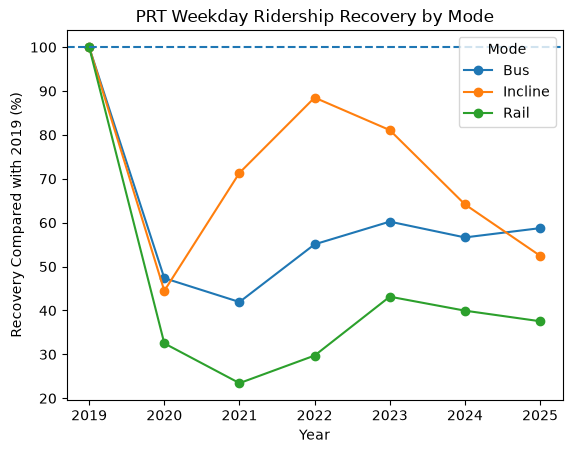

In [49]:
recovery_plot.plot(
    marker="o"
)

plt.title("PRT Weekday Ridership Recovery by Mode")
plt.xlabel("Year")
plt.ylabel("Recovery Compared with 2019 (%)")
plt.axhline(100, linestyle="--")
plt.legend(title="Mode")
plt.show()

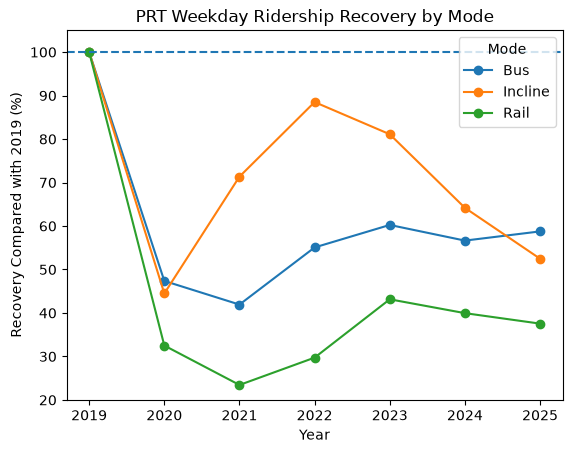

In [50]:
recovery_plot.plot(
    marker="o"
)

plt.title("PRT Weekday Ridership Recovery by Mode")
plt.xlabel("Year")
plt.ylabel("Recovery Compared with 2019 (%)")
plt.axhline(100, linestyle="--")
plt.ylim(20, 105)
plt.legend(title="Mode", loc="best")
plt.show()

## Final Results

In [51]:
final_results = recovery_summary[
    ["Year", "Mode", "Recovery_Percent", "YoY_Recovery_Point_Change"]
].copy()

In [52]:
final_results["Recovery_Percent"] = final_results["Recovery_Percent"].round(1)
final_results["YoY_Recovery_Point_Change"] = final_results[
    "YoY_Recovery_Point_Change"
].round(1)

In [53]:
final_results

,Year,Mode,Recovery_Percent,YoY_Recovery_Point_Change
0,2019,Bus,100.0,NaN
1,2020,Bus,47.4,-52.6
2,2021,Bus,41.9,-5.4
3,2022,Bus,55.1,13.1
4,2023,Bus,60.2,5.2
5,2024,Bus,56.6,-3.6
6,2025,Bus,58.8,2.1
7,2019,Incline,100.0,NaN
8,2020,Incline,44.5,-55.5
9,2021,Incline,71.4,26.9


## Key Findings

- All three modes remained below their 2019 weekday ridership levels through 2025.
- Bus ridership fell to 41.9% of its 2019 level in 2021, then recovered to 60.2% in 2023. By 2025, bus ridership was at 58.8% of its 2019 level.
- Rail experienced the weakest recovery. It fell to 23.4% of its 2019 level in 2021, increased to 43.1% in 2023, and declined to 37.5% by 2025.
- Incline ridership followed a different pattern. It recovered to 88.5% of the comparable 2019 level in 2022, but then declined to 52.5% by 2025.
- By 2025, bus had the highest recovery relative to 2019, followed by incline and rail.

## Analysis Notes and Limitations

- The analysis uses weekday ridership only and compares each mode with its own 2019 baseline.
- Bus and rail have complete monthly coverage from 2019 through 2025.
- Incline data are incomplete in 2022, 2023, and 2024, and incline ridership varies substantially by season. For those years, recovery was calculated using only the months available in that year and comparing them with the same months in 2019.
- The MNT and MNT1 route records were excluded from the analysis because their mode classifications were inconsistent and their ridership totals were very small.
- Rail includes an additional route code, SWL, in 2024 and 2025, so changes in rail service structure or route coding may affect comparisons across years.
- Ridership changes may also reflect factors beyond the COVID-19 disruption, including service changes, commuting patterns, tourism, construction, and other changes in travel behavior.

## Conclusion and Recommendations

The results show that weekday ridership recovery was different across bus, rail, and incline service. By 2025, bus ridership had recovered to 58.8% of its 2019 level, incline was at 52.5%, and rail was at 37.5%.

Based on these results, I think PRT should focus more attention on rail because it had the weakest recovery. One recommendation would be to review rail ridership by route, station, and time of day to find where the largest declines happened. If certain times or locations consistently have low ridership, PRT could consider changing service frequency or schedules instead of treating the entire rail system the same.

PRT should also look at what has helped bus ridership recover more strongly. If certain bus routes, schedules, or service areas recovered better than others, PRT could use those patterns when deciding where additional service or funding would have the biggest impact.

I would also recommend being cautious about putting additional money into the incline based only on these results. The incline had service closures and missing months in several years, so more complete data would be needed before making a major investment decision.

Overall, I would recommend that PRT use these results to target future analysis and funding decisions. Rail should receive the most attention because of its lower recovery, while successful bus service patterns could be studied and potentially expanded.